# Milo Differential Abundance Testing for Healthy Dataset

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo  ## For mouse gastrulation data 
import anndata
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3

import milopy.core as milo
import milopy.plot as milopl

In [2]:
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo_ref_hvg.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_scArches_full.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_scArches_labeled_full.h5ad")

In [2]:
query_studies = ['Meyer_2021_3prime', 'Meyer_2021_5prime']

In [3]:
def get_avg_da_per_cell(data):
    # Input: data
    #     whole anndata object (either denovo_recalc, denovo_ref, scarches_unlabeled, scarches_labeled)
    # Output: cells_DA_avg
    #     vector containing for all cells the average logFC over the nhoods this cell is part of
    
    # get vector with all cells and DA info: non-index cells have logFC of 0, index-cells have logFC != 0
    DA_per_cell = pd.merge(data.obs, data.uns["nhood_adata"].obs[["index_cell","logFC"]], how="left", left_index=True, right_on="index_cell")[["index_cell","logFC"]].fillna(0)
    DA_per_cell.index = DA_per_cell.index_cell
    DA_per_cell = DA_per_cell["logFC"]
    
    # get cells x nhoods matrix with logFC values instead of neighborhood assignment
    cells_nh_DA = (data.obsm["nhoods"].T).multiply(DA_per_cell).T
    
    # average over logFC values for each nhood
    nh_DA_avg = cells_nh_DA.sum(axis=0).A1/cells_nh_DA.getnnz(axis=0)
    
    # get cells x nhoods matrix with average logFC values per nhood instead of nhood assignment
    cells_nh_DA_avg = (data.obsm["nhoods"]).multiply(nh_DA_avg)
    
    # get vector with average logFC for all cells over all nhoods each cell is part of
    cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)
    pd.DataFrame(cells_DA_avg).fillna(0, inplace=True)
    
    #output
    return cells_DA_avg

# 1. De-Novo with recalculated HVGs

In [132]:
denovo_recalc.obs["origin"] = "reference"
denovo_recalc.obs.loc[denovo_recalc.obs.dataset.isin(query_studies),"origin"] = "query"

In [133]:
k = 50 #number of neighbors 50
n = 30 #number of pcs 30

In [134]:
sc.pp.neighbors(denovo_recalc, n_neighbors=k, n_pcs=n, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:14:17)


In [136]:
sc.tl.umap(denovo_recalc)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:25:03)


... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


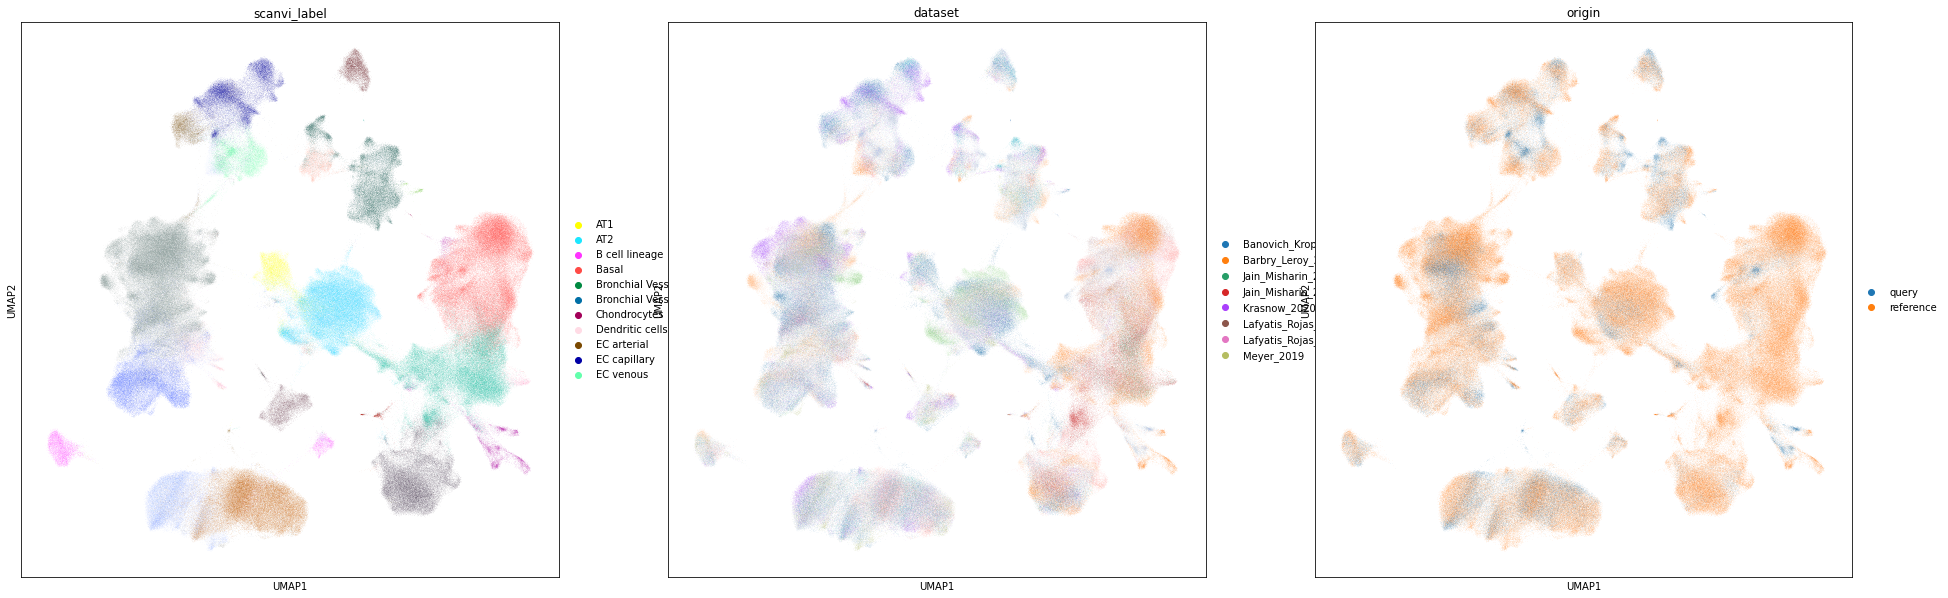

In [137]:
sc.pl.umap(denovo_recalc, color=["scanvi_label","dataset", "origin"])

In [ ]:
milo.make_nhoods(denovo_recalc, prop=1)

In [ ]:
nhood_size = np.array(denovo_recalc.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [ ]:
milo.count_nhoods(denovo_recalc, sample_col="sample")

In [ ]:
denovo_recalc.obs["origin_continuous"] = denovo_recalc.obs["origin"].cat.codes

In [ ]:
milo.DA_nhoods(denovo_recalc, design="~origin_continuous")

In [ ]:
denovo_recalc.obs['row_num'] = np.arange(len(denovo_recalc))

In [ ]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(denovo_recalc.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(denovo_recalc.uns["nhood_adata"].obs.logFC, -np.log10(denovo_recalc.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [ ]:
import milopy.utils
milopy.utils.build_nhood_graph(denovo_recalc)

In [ ]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(denovo_recalc, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (De-Novo with recalc HVGs)"
                       )

In [ ]:
milopy.utils.annotate_nhoods(denovo_recalc, anno_col='C_scANVI')

In [ ]:
plt.hist(denovo_recalc.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [ ]:
denovo_recalc.uns['nhood_adata'].obs.loc[denovo_recalc.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

In [ ]:
sc.pl.violin(denovo_recalc.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

In [77]:
denovo_recalc.obs["has_nhood"] = "yes"

In [78]:
M = (np.sum(denovo_recalc.obsm["nhoods"],axis=1)==0)
mask_no_nhood = np.squeeze(np.asarray(M))

In [79]:
denovo_recalc.obs.loc[mask_no_nhood,"has_nhood"] = "no"

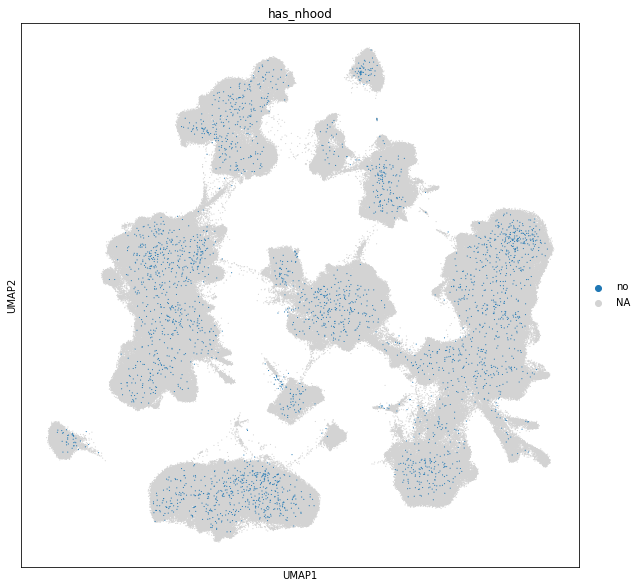

In [82]:
sc.pl.umap(denovo_recalc, color="has_nhood", size=5, groups=["no"])

In [ ]:
denovo_recalc.obs["logFC_avg"] = get_avg_da_per_cell(denovo_recalc)

In [24]:
denovo_recalc_save = denovo_recalc.copy()

In [25]:
del denovo_recalc_save.uns["nhood_adata"]

In [26]:
denovo_recalc_save.write("/home/jan.domke/server_home/Comparison/Data/Healthy/denovo_recalc_milo.h5ad")

... storing 'highly_variable_intersection-0' as categorical


# 2. unlabeled scArches

In [27]:
scarches_unlabeled.obs["origin"] = "reference"
scarches_unlabeled.obs.loc[scarches_unlabeled.obs.dataset.isin(query_studies),"origin"] = "query"

In [28]:
sc.pp.neighbors(scarches_unlabeled, n_neighbors=50, n_pcs=30, use_rep="X_scArches")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:10:11)


In [29]:
sc.tl.umap(scarches_unlabeled)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:24:10)


... storing 'origin' as categorical


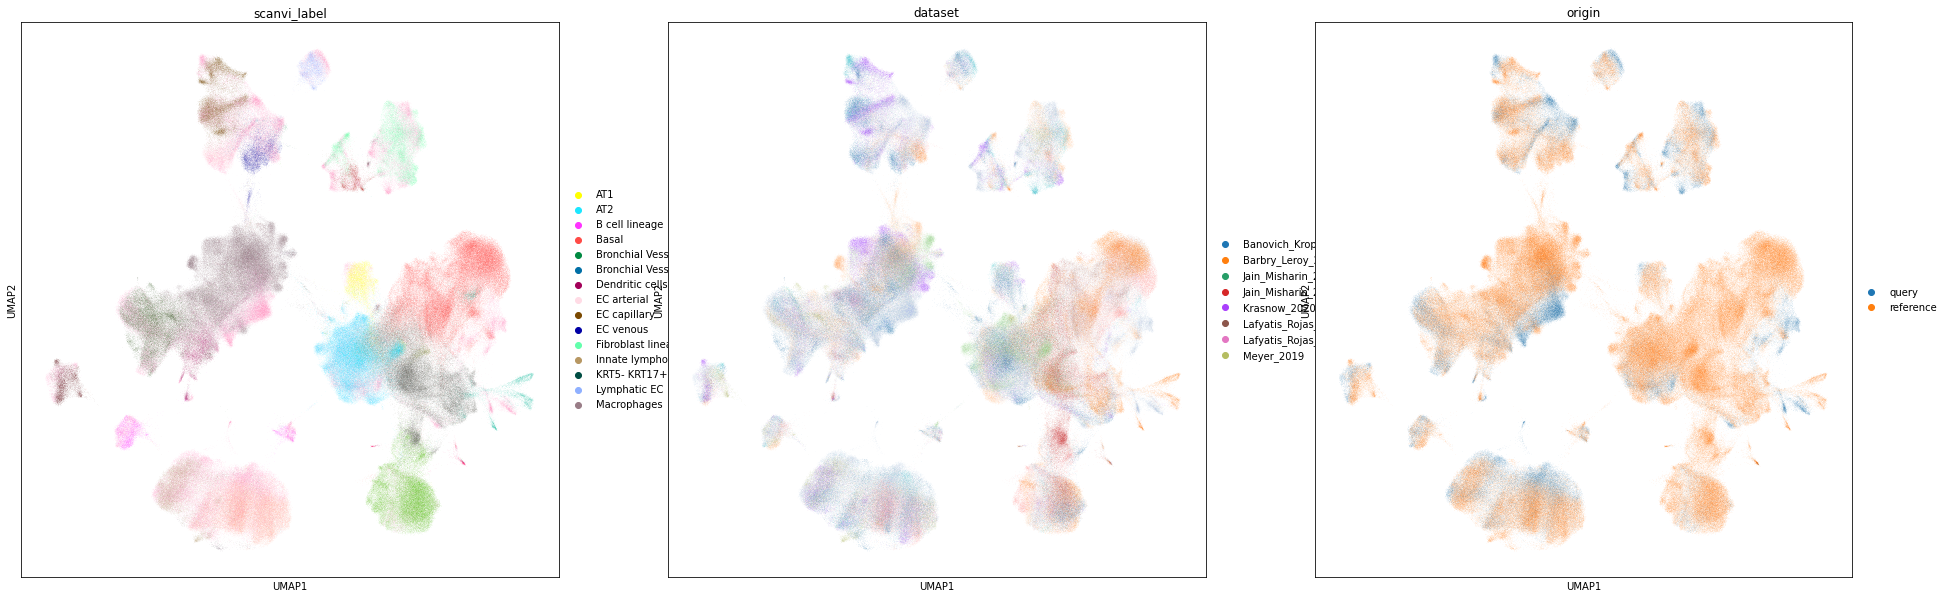

In [30]:
sc.pl.umap(scarches_unlabeled, color=["scanvi_label","dataset", "origin"])

In [31]:
milo.make_nhoods(scarches_unlabeled, prop=0.1)

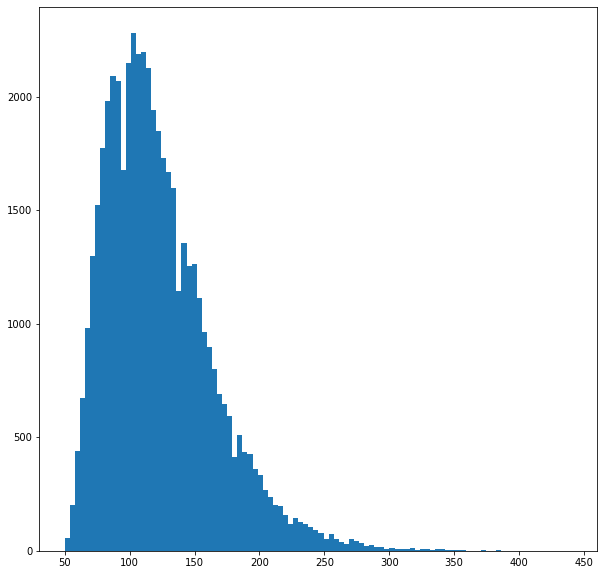

In [32]:
nhood_size = np.array(scarches_unlabeled.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [33]:
milo.count_nhoods(scarches_unlabeled, sample_col="sample")

In [34]:
scarches_unlabeled.obs["origin_continuous"] = scarches_unlabeled.obs["origin"].cat.codes

In [35]:
milo.DA_nhoods(scarches_unlabeled, design="~origin_continuous")

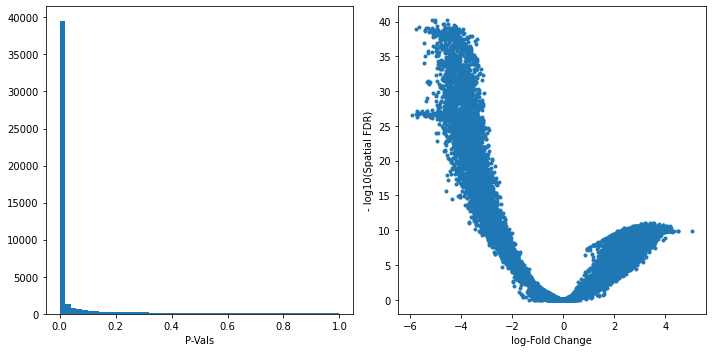

In [36]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(scarches_unlabeled.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(scarches_unlabeled.uns["nhood_adata"].obs.logFC, -np.log10(scarches_unlabeled.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [37]:
milopy.utils.build_nhood_graph(scarches_unlabeled)

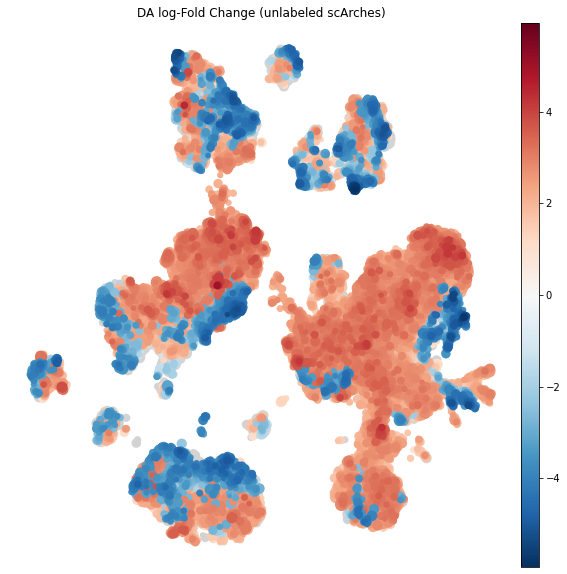

In [38]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(scarches_unlabeled, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (unlabeled scArches)"
                       )

In [39]:
milopy.utils.annotate_nhoods(scarches_unlabeled, anno_col='C_scArches')

Text(0.5, 0, 'celltype fraction')

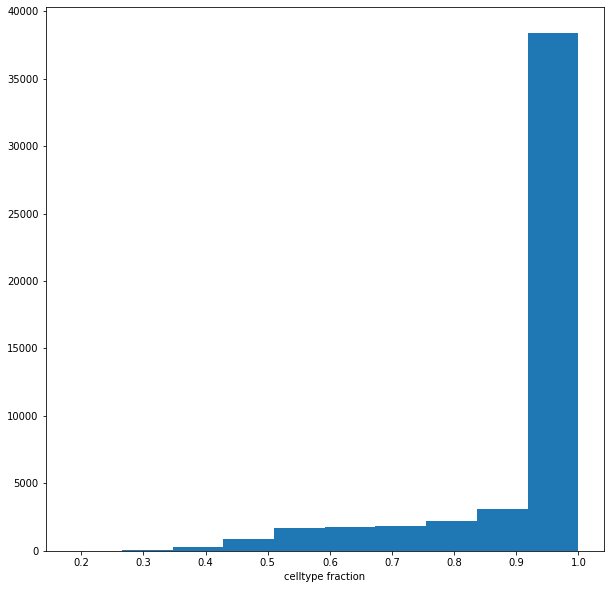

In [40]:
plt.hist(scarches_unlabeled.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [41]:
scarches_unlabeled.uns['nhood_adata'].obs.loc[scarches_unlabeled.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


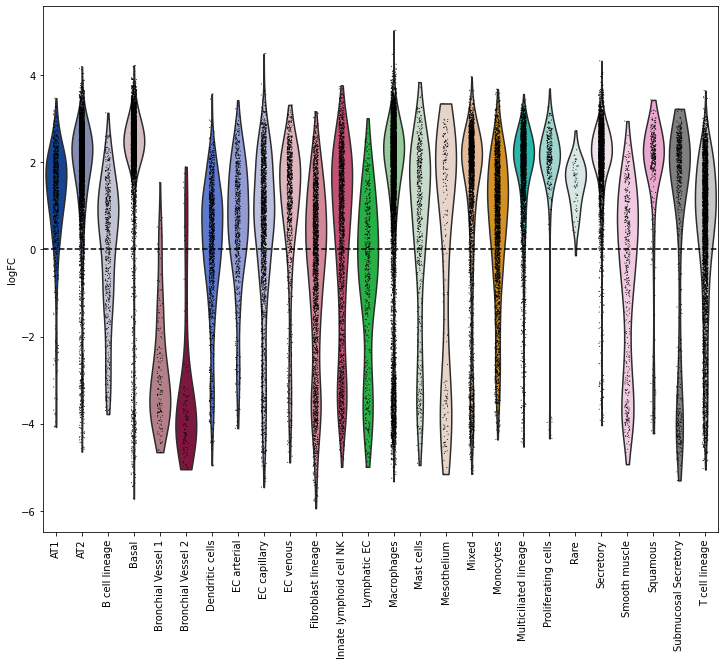

In [42]:
sc.pl.violin(scarches_unlabeled.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

In [43]:
scarches_unlabeled.obs["logFC_avg"] = get_avg_da_per_cell(scarches_unlabeled)

In [44]:
scarches_unlabeled_save = scarches_unlabeled.copy()

In [45]:
del scarches_unlabeled_save.uns["nhood_adata"]

In [46]:
scarches_unlabeled_save.write("/home/jan.domke/server_home/Comparison/Data/Healthy/scarches_unlabeled_milo.h5ad")

# 3. labeled scArches

In [47]:
scarches_labeled.obs["origin"] = "reference"
scarches_labeled.obs.loc[scarches_labeled.obs.dataset.isin(query_studies),"origin"] = "query"

In [48]:
sc.pp.neighbors(scarches_labeled, n_neighbors=50, n_pcs=30, use_rep="X_scArches")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:10:29)


In [49]:
sc.tl.umap(scarches_labeled)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:23:54)


... storing 'origin' as categorical


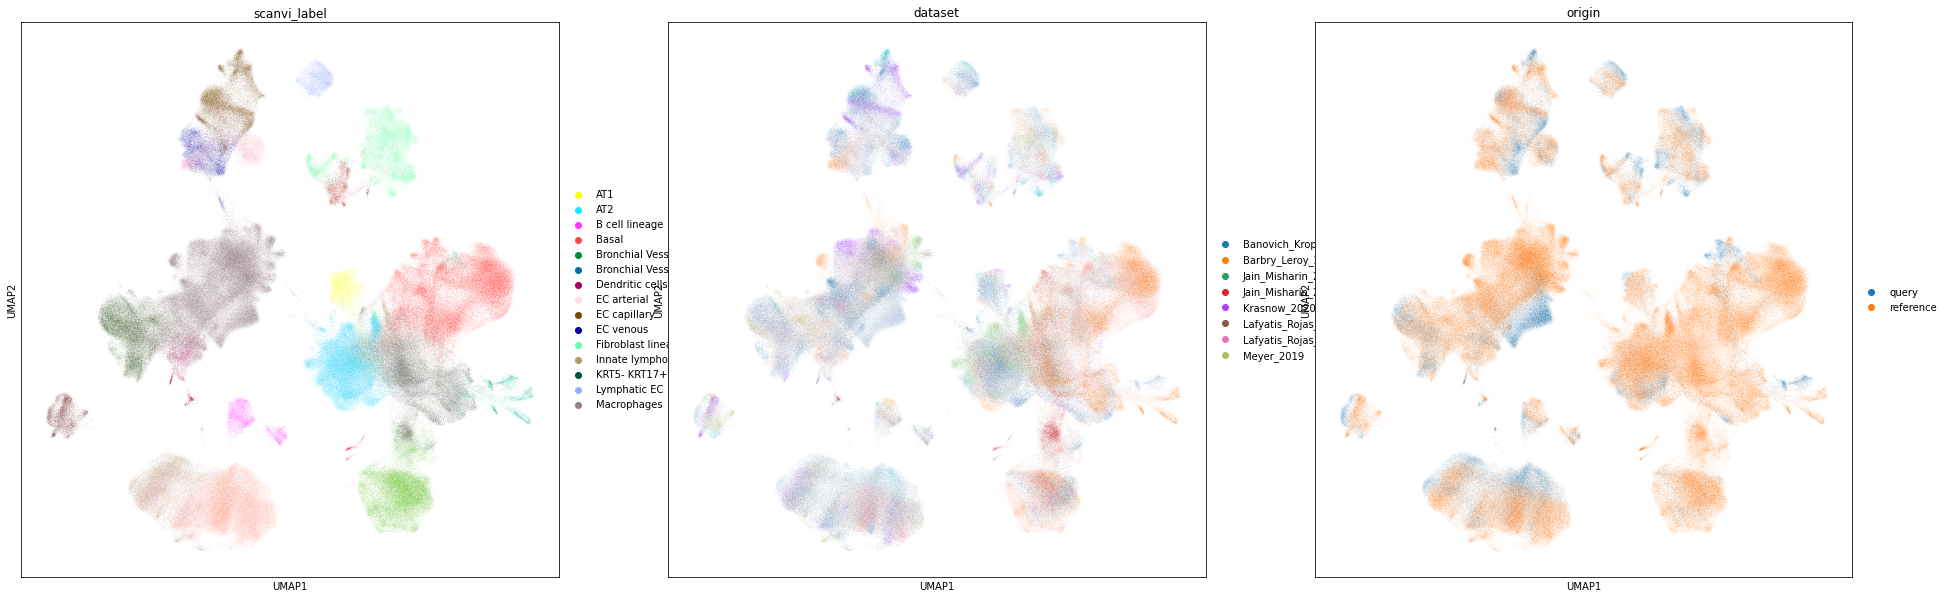

In [50]:
sc.pl.umap(scarches_labeled, color=["scanvi_label","dataset", "origin"])

In [51]:
milo.make_nhoods(scarches_labeled, prop=0.1)

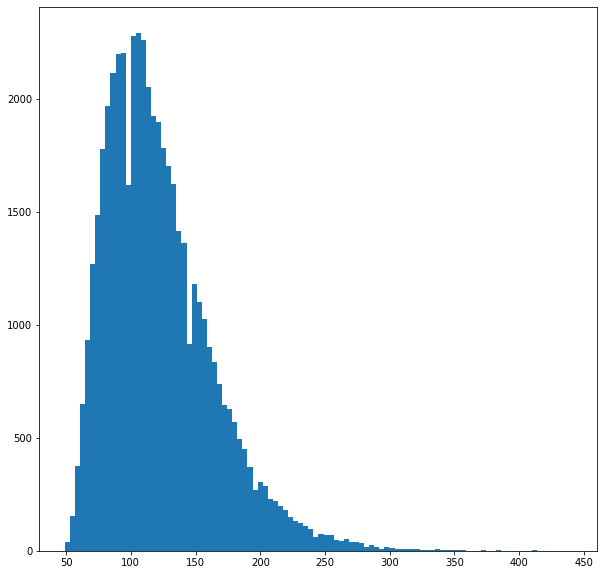

In [52]:
nhood_size = np.array(scarches_labeled.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [53]:
milo.count_nhoods(scarches_labeled, sample_col="sample")

In [54]:
scarches_labeled.obs["origin_continuous"] = scarches_labeled.obs["origin"].cat.codes

In [55]:
milo.DA_nhoods(scarches_labeled, design="~origin_continuous")

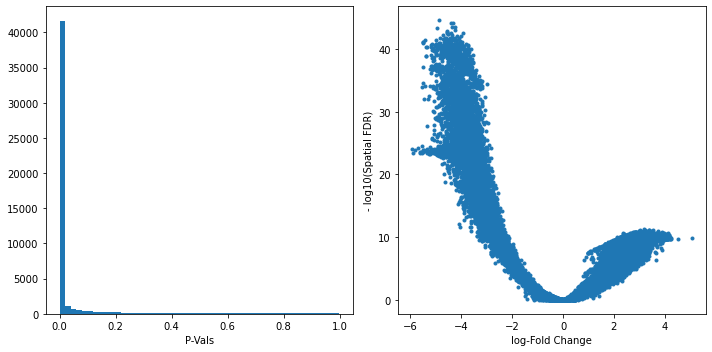

In [56]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(scarches_labeled.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(scarches_labeled.uns["nhood_adata"].obs.logFC, -np.log10(scarches_labeled.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [57]:
milopy.utils.build_nhood_graph(scarches_labeled)

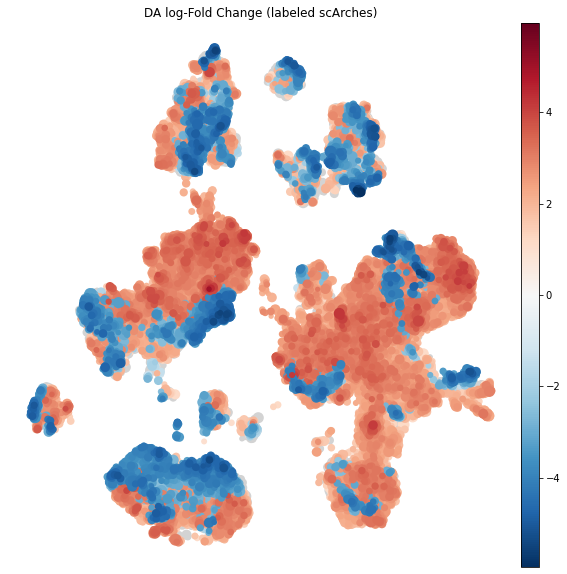

In [58]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(scarches_labeled, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (labeled scArches)"
                       )

In [59]:
milopy.utils.annotate_nhoods(scarches_labeled, anno_col='scanvi_label')

Text(0.5, 0, 'celltype fraction')

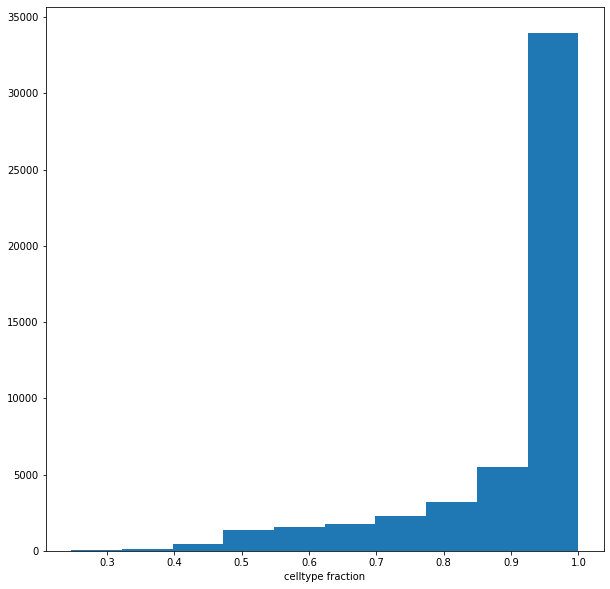

In [60]:
plt.hist(scarches_labeled.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [61]:
scarches_labeled.uns['nhood_adata'].obs.loc[scarches_labeled.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


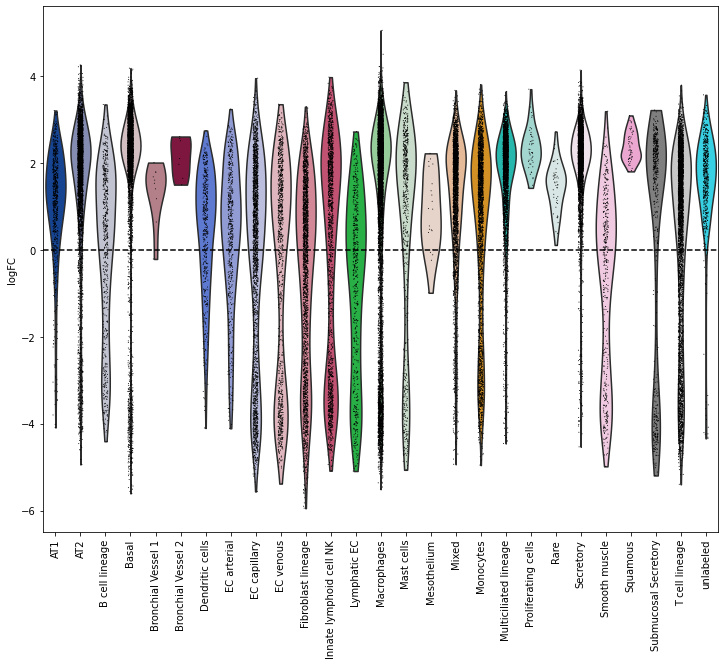

In [62]:
sc.pl.violin(scarches_labeled.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

In [63]:
scarches_labeled.obs["logFC_avg"] = get_avg_da_per_cell(scarches_labeled)

In [64]:
scarches_labeled_save = scarches_labeled.copy()

In [65]:
del scarches_labeled_save.uns["nhood_adata"]

In [66]:
scarches_labeled_save.write("/home/jan.domke/server_home/Comparison/Data/Healthy/scarches_labeled_milo.h5ad")

# 4. De-Novo with reference HVGs

In [67]:
denovo_ref.obs["origin"] = "reference"
denovo_ref.obs.loc[denovo_ref.obs.dataset.isin(query_studies),"origin"] = "query"

In [68]:
sc.pp.neighbors(denovo_ref, n_neighbors=50, n_pcs=30, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:09:14)


In [69]:
sc.tl.umap(denovo_ref)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:23:47)


... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


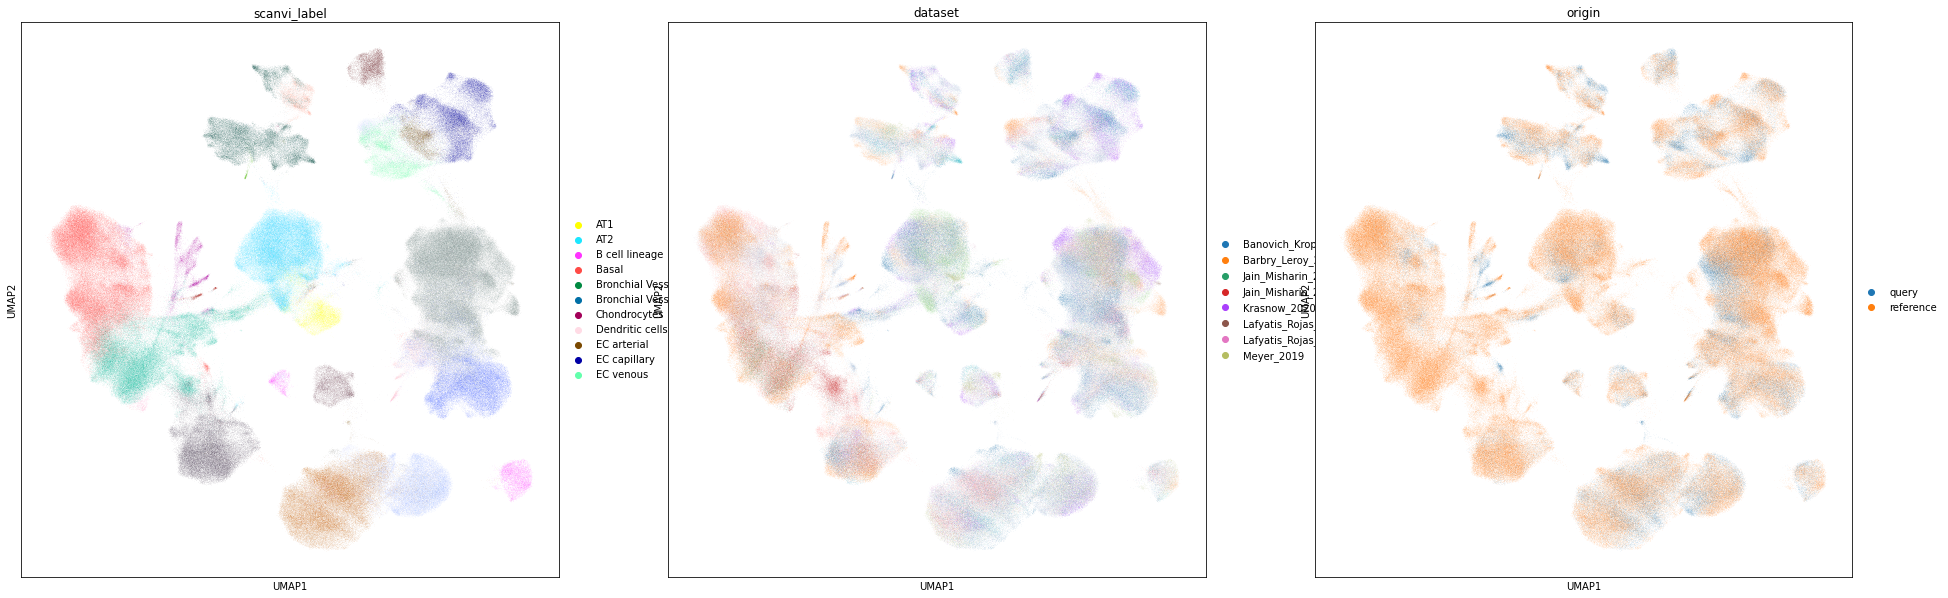

In [70]:
sc.pl.umap(denovo_ref, color=["scanvi_label","dataset", "origin"])

In [71]:
milo.make_nhoods(denovo_ref, prop=0.1)

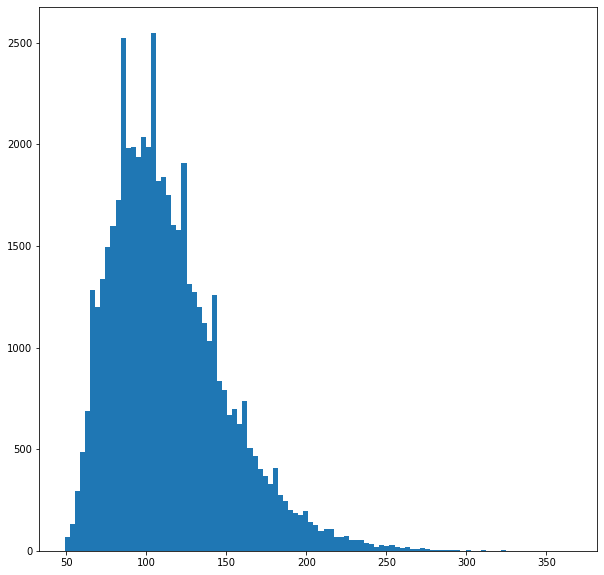

In [72]:
nhood_size = np.array(denovo_ref.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [73]:
milo.count_nhoods(denovo_ref, sample_col="sample")

In [74]:
denovo_ref.obs["origin_continuous"] = denovo_ref.obs["origin"].cat.codes

In [75]:
milo.DA_nhoods(denovo_ref, design="~origin_continuous")

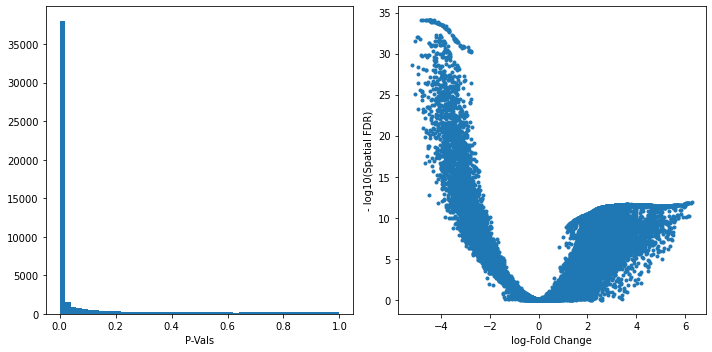

In [76]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(denovo_ref.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(denovo_ref.uns["nhood_adata"].obs.logFC, -np.log10(denovo_ref.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [77]:
milopy.utils.build_nhood_graph(denovo_ref)

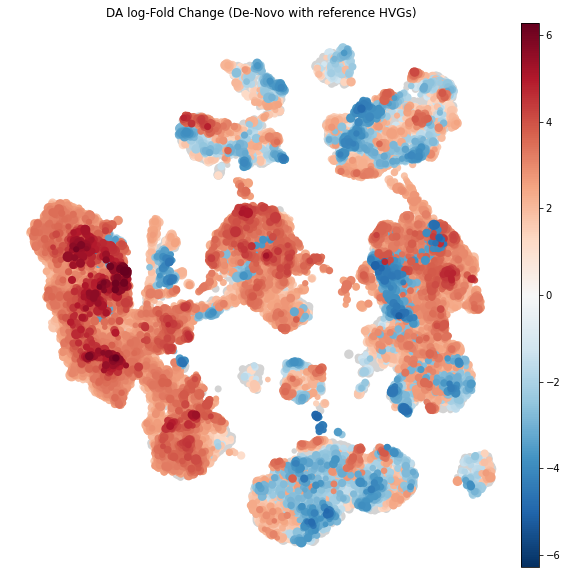

In [78]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(denovo_ref, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (De-Novo with reference HVGs)"
                       )

In [79]:
milopy.utils.annotate_nhoods(denovo_ref, anno_col='scanvi_label')

Text(0.5, 0, 'celltype fraction')

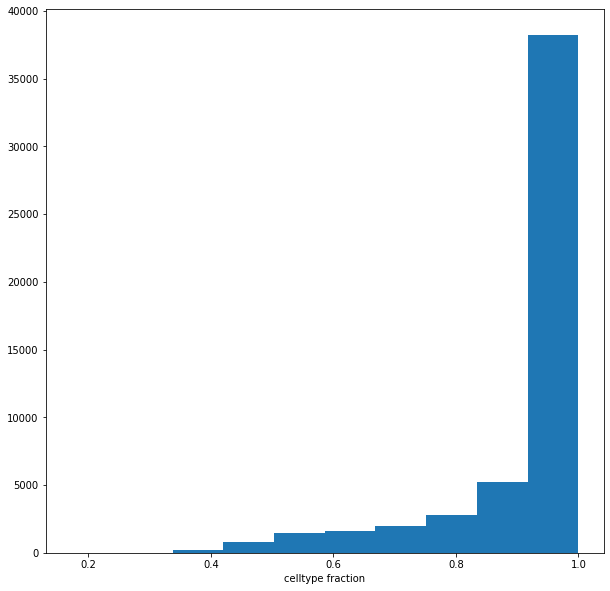

In [80]:
plt.hist(denovo_ref.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [81]:
denovo_ref.uns['nhood_adata'].obs.loc[denovo_ref.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


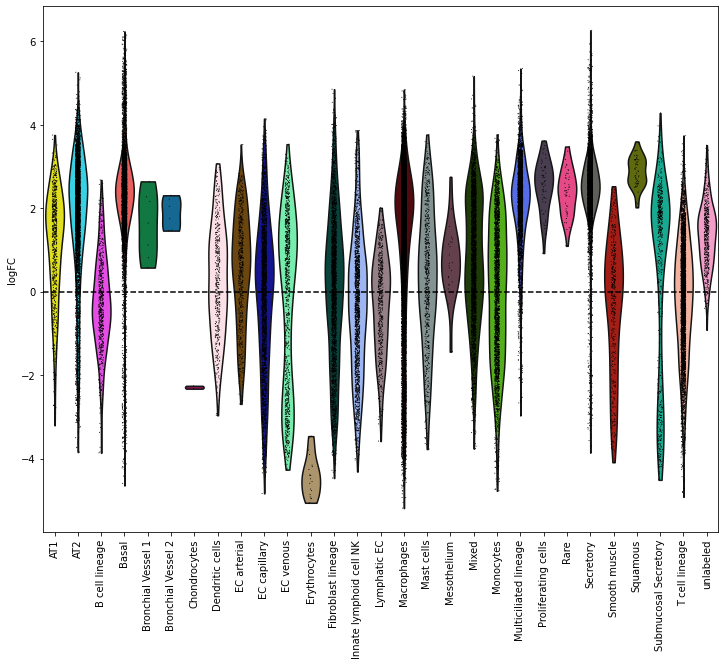

In [82]:
sc.pl.violin(denovo_ref.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

In [83]:
denovo_ref.obs["logFC_avg"] = get_avg_da_per_cell(denovo_ref)

In [84]:
denovo_ref_save = denovo_ref.copy()

In [85]:
del denovo_ref_save.uns["nhood_adata"]

In [86]:
denovo_ref_save.write("/home/jan.domke/server_home/Comparison/Data/Healthy/denovo_ref_milo.h5ad")

# Plot differences

In [4]:
denovo_recalc = sc.read("/home/jan.domke/server_home/Comparison/Data/Healthy/denovo_recalc_milo.h5ad")
denovo_ref = sc.read("/home/jan.domke/server_home/Comparison/Data/Healthy/denovo_ref_milo.h5ad")
scarches_unlabeled = sc.read("/home/jan.domke/server_home/Comparison/Data/Healthy/scarches_unlabeled_milo.h5ad")
scarches_labeled = sc.read("/home/jan.domke/server_home/Comparison/Data/Healthy/scarches_labeled_milo.h5ad")

In [5]:
scarches_unlabeled.obs["diff_denovo_recalc"] = scarches_unlabeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg
scarches_unlabeled.obs["diff_scArches_labeled"] = scarches_unlabeled.obs.logFC_avg - scarches_labeled.obs.logFC_avg
scarches_labeled.obs["diff_denovo_recalc"] = scarches_labeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg
denovo_ref.obs["diff_denovo_recalc"] = denovo_ref.obs.logFC_avg - denovo_recalc.obs.logFC_avg
denovo_recalc.obs["diff_scArches_unlabeled"] = denovo_recalc.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg
denovo_recalc.obs["diff_scArches_unlabeled_comp"] = scarches_unlabeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg

In [6]:
colordict = dict(zip(denovo_recalc.obs["scanvi_label"].cat.categories, denovo_recalc.uns["scanvi_label_colors"]))

In [7]:
import pickle
with open('/home/jan.domke/server_home/Comparison/Data/colordict.pkl', 'wb') as f:
    pickle.dump(colordict, f)

In [8]:
from matplotlib.colors import to_hex
cat_scarches_unlabeled = scarches_unlabeled.obs["scanvi_label"].cat.categories
cat_scarches_labeled = scarches_labeled.obs["scanvi_label"].cat.categories
cat_denovo_recalc = denovo_recalc.obs["scanvi_label"].cat.categories
cat_denovo_ref = denovo_ref.obs["scanvi_label"].cat.categories

colors_list_scarches_unlabeled = [to_hex(colordict[k], keep_alpha=True) for k in cat_scarches_unlabeled]
colors_list_scarches_labeled = [to_hex(colordict[k], keep_alpha=True) for k in cat_scarches_labeled]
colors_list_denovo_recalc = [to_hex(colordict[k], keep_alpha=True) for k in cat_denovo_recalc]
colors_list_denovo_ref = [to_hex(colordict[k], keep_alpha=True) for k in cat_denovo_ref]

In [9]:
del denovo_recalc.uns['scanvi_label_colors']
del denovo_ref.uns['scanvi_label_colors']
del scarches_unlabeled.uns['scanvi_label_colors']
del scarches_labeled.uns['scanvi_label_colors']

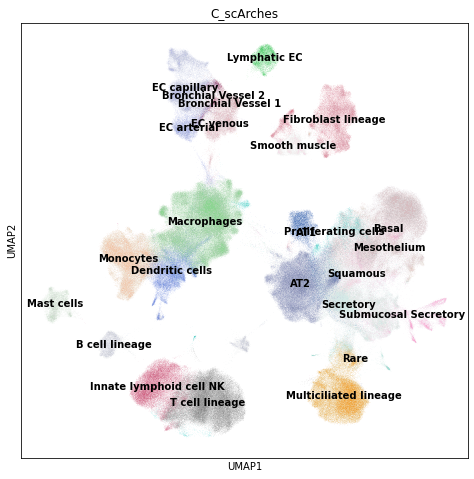

In [10]:
sc.pl.umap(scarches_unlabeled, color = "C_scArches", legend_loc = "on data")

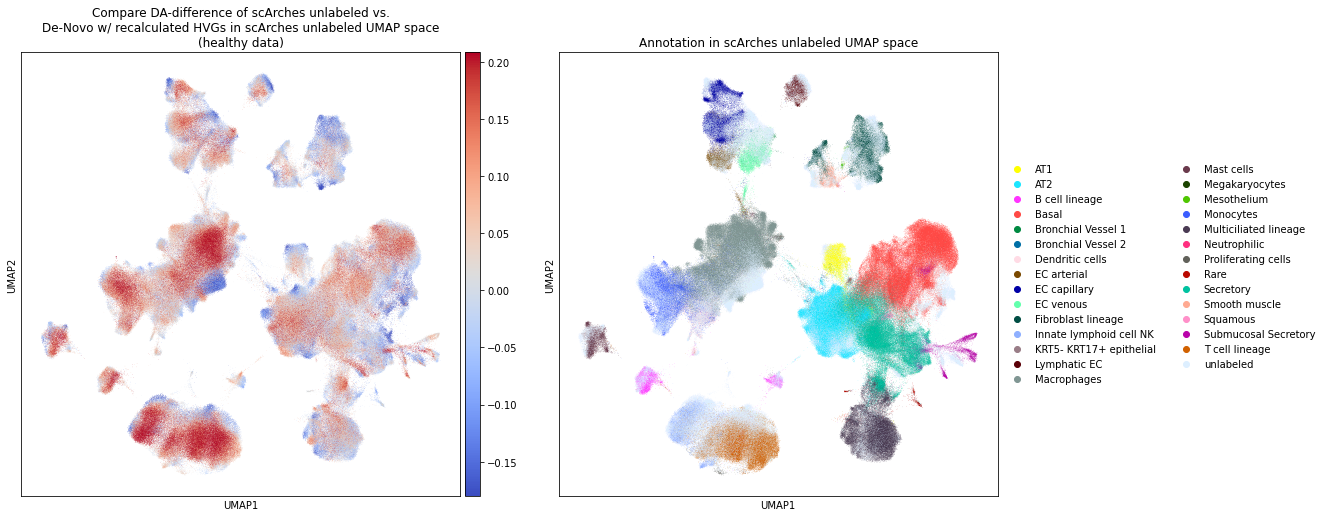

In [11]:
sc.pl.umap(scarches_unlabeled, color=["diff_denovo_recalc", "scanvi_label"],
           vmin="p5", vmax="p95",color_map="coolwarm", palette = colordict, size = 0.5,
           title = ["Compare DA-difference of scArches unlabeled vs.\nDe-Novo w/ recalculated HVGs in scArches unlabeled UMAP space\n(healthy data)", 
                   "Annotation in scArches unlabeled UMAP space" ])

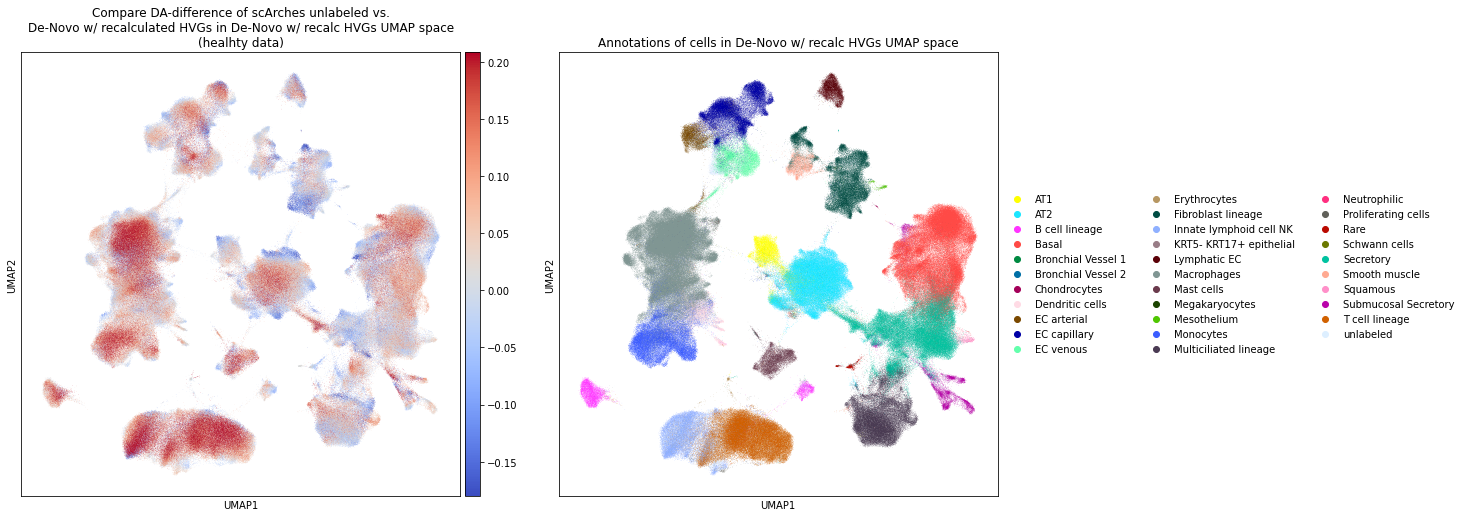

In [12]:
sc.pl.umap(denovo_recalc, color=["diff_scArches_unlabeled_comp", "scanvi_label"], 
           vmin="p5", vmax="p95", color_map = "coolwarm", palette = colordict, size = 0.5,
           title = ["Compare DA-difference of scArches unlabeled vs.\nDe-Novo w/ recalculated HVGs in De-Novo w/ recalc HVGs UMAP space\n(healhty data)", 
                    "Annotations of cells in De-Novo w/ recalc HVGs UMAP space"])

# Violin Plots 

In [15]:
scarches_unlabeled.obs["diff_denovo_recalc_abs"] = abs(scarches_unlabeled.obs.diff_denovo_recalc)

In [24]:
scarches_unlabeled.obs.groupby("scanvi_label_original")["diff_denovo_recalc_abs"].median().sort_values().index

CategoricalIndex(['Mesothelium', 'Erythrocytes', 'Rare', 'Dendritic cells',
                  'B cell lineage', 'Chondrocytes', 'EC arterial',
                  'Smooth muscle', 'AT1', 'Monocytes', 'Schwann cells',
                  'Megakaryocytes', 'Submucosal Secretory', 'EC venous', 'AT2',
                  'Fibroblast lineage', 'EC capillary', 'Lymphatic EC',
                  'Secretory', 'T cell lineage', 'Innate lymphoid cell NK',
                  'Mast cells', 'Basal', 'Macrophages',
                  'Multiciliated lineage'],
                 categories=['AT1', 'AT2', 'B cell lineage', 'Basal', 'Chondrocytes', 'Dendritic cells', 'EC arterial', 'EC capillary', ...], ordered=False, name='scanvi_label_original', dtype='category')

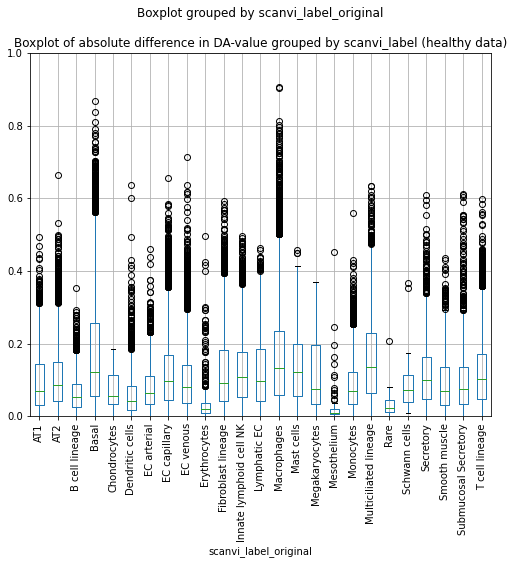

In [14]:
scarches_unlabeled.obs.boxplot(column='diff_denovo_recalc_abs',by='scanvi_label_original')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by scanvi_label (healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig("/home/jan.domke/server_home/Comparison/Data/Healthy/Plots/healthy_boxplot_scanvi_label.jpg")

In [15]:
new_cell_labels_lvl3 = ["Erythrocytes", "Schwann myelinating", "Schwann nonmyelinating", "Megakaryocytes"]

rare_cell_labels_lvl3 = ["Rare"]
rare_cell_labels_lvl4 = ["Neuroendocrine", "Regulatory T cells", "Gamma-delta T cells", "ILCs", "NKT cells", "NK cells"]
rare_cell_labels_lvl5 = ['CD4 T cells MAIT','CD4 T cells naive','CD4T cells TRM','CD8 T cells GZMK+','CD8 T cells ME','CD8 T cells TRM','NK_ITGAD+','NK_XCL1+']

new_lvl3 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_3"].isin(new_cell_labels_lvl3)]
new_lvl3.obs["diff_denovo_recalc_abs"] = abs(new_lvl3.obs.diff_denovo_recalc)

rare_lvl3 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_3"].isin(rare_cell_labels_lvl3)]
rare_lvl4 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_4"].isin(rare_cell_labels_lvl4)]
rare_lvl5 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_5"].isin(rare_cell_labels_lvl5)]
rare_lvl3.obs["diff_denovo_recalc_abs"] = abs(rare_lvl3.obs.diff_denovo_recalc)
rare_lvl4.obs["diff_denovo_recalc_abs"] = abs(rare_lvl4.obs.diff_denovo_recalc)
rare_lvl5.obs["diff_denovo_recalc_abs"] = abs(rare_lvl5.obs.diff_denovo_recalc)

Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.


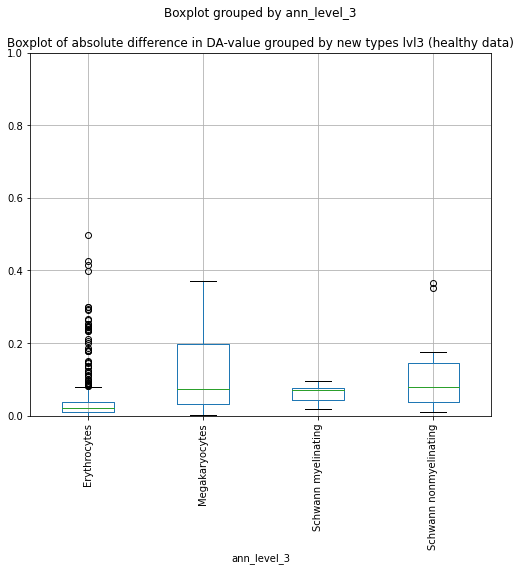

In [16]:
new_lvl3.obs.boxplot(column='diff_denovo_recalc_abs',by='ann_level_3')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by new types lvl3 (healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig("/home/jan.domke/server_home/Comparison/Data/Healthy/Plots/healthy_boxplot_new_lvl3.jpg")

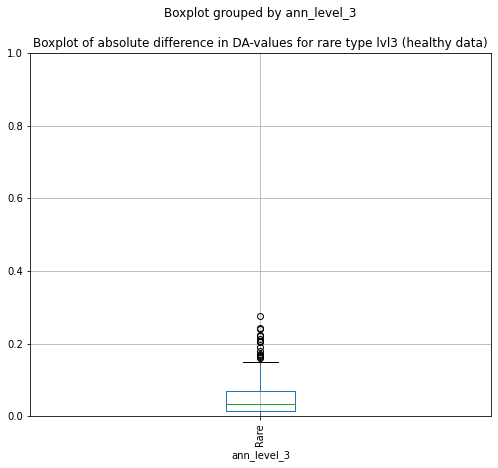

In [17]:
rare_lvl3.obs.boxplot(column='diff_denovo_recalc_abs',by='ann_level_3')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-values for rare type lvl3 (healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig("/home/jan.domke/server_home/Comparison/Data/Healthy/Plots/healthy_boxplot_rare_lvl3.jpg")

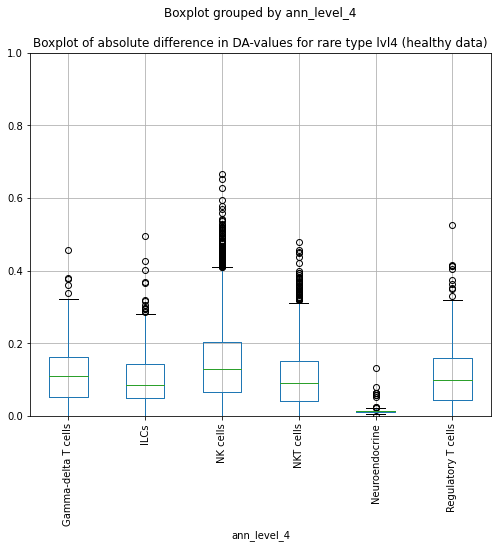

In [18]:
rare_lvl4.obs.boxplot(column='diff_denovo_recalc_abs',by='ann_level_4')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-values for rare type lvl4 (healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig("/home/jan.domke/server_home/Comparison/Data/Healthy/Plots/healthy_boxplot_rare_lvl4.jpg")

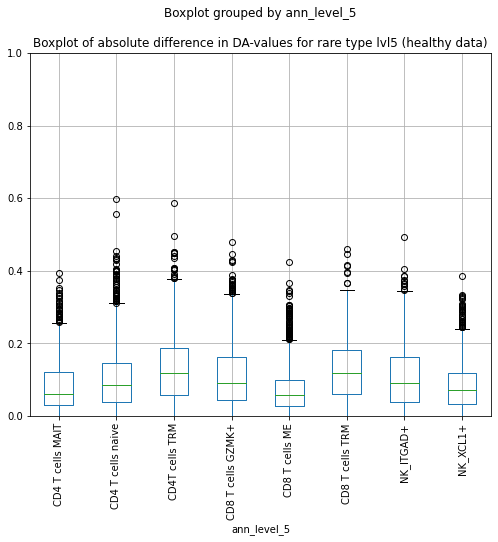

In [19]:
rare_lvl5.obs.boxplot(column='diff_denovo_recalc_abs',by='ann_level_5')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-values for rare type lvl5 (healthy data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig("/home/jan.domke/server_home/Comparison/Data/Healthy/Plots/healthy_boxplot_rare_lvl5.jpg")

# Clustering analysis

In [23]:
sc.tl.leiden(denovo_recalc, resolution= 0.1)

running Leiden clustering
    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:12:32)


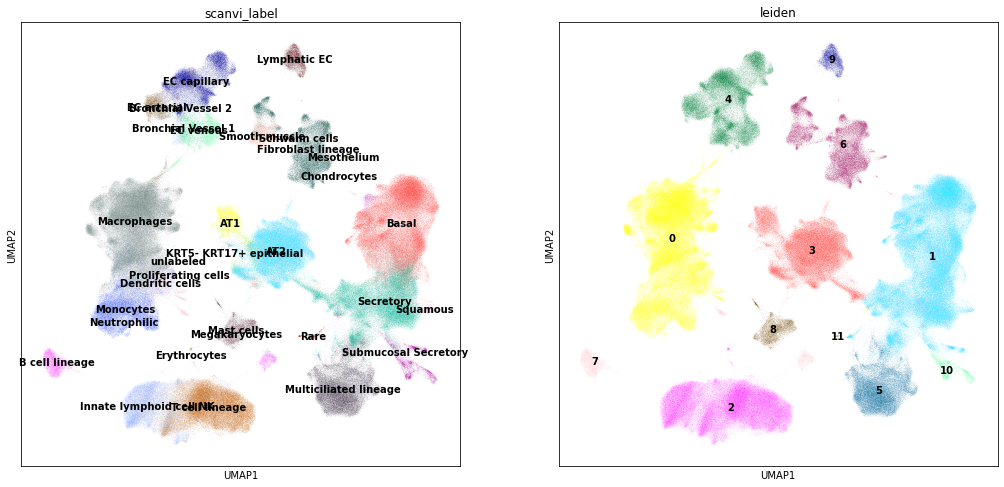

In [24]:
sc.pl.umap(denovo_recalc, color=["scanvi_label","leiden"], legend_loc="on data")

In [25]:
subset_immune = denovo_recalc[(denovo_recalc.obs.leiden == "0") | (denovo_recalc.obs.leiden == "2")].copy()

In [26]:
sc.pp.neighbors(subset_immune, n_neighbors=50, n_pcs=30, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:04:46)


In [27]:
sc.tl.umap(subset_immune)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:08:56)


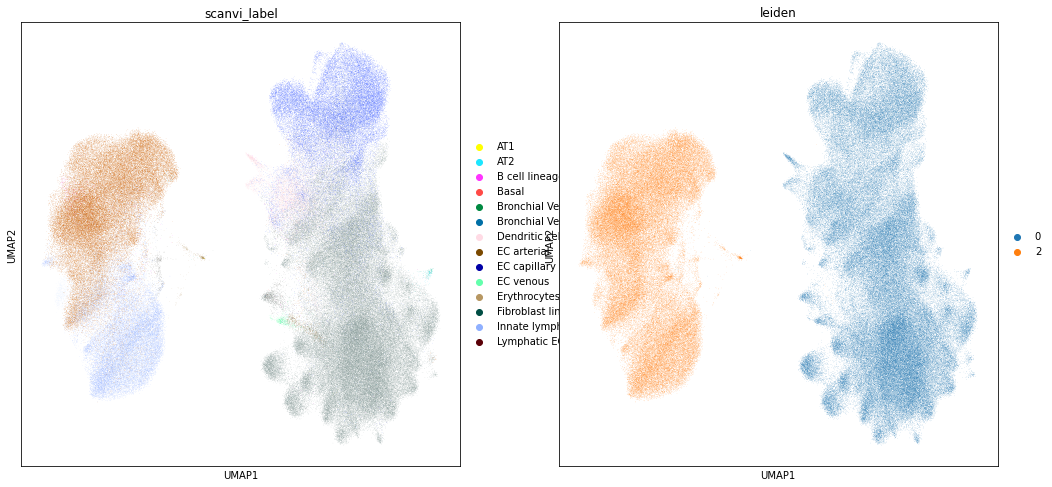

In [28]:
sc.pl.umap(subset_immune, color=["scanvi_label","leiden"])

In [29]:
sc.tl.leiden(subset_immune, resolution= 0.5,key_added = "leiden_sub")

running Leiden clustering
    finished: found 13 clusters and added
    'leiden_sub', the cluster labels (adata.obs, categorical) (0:09:50)


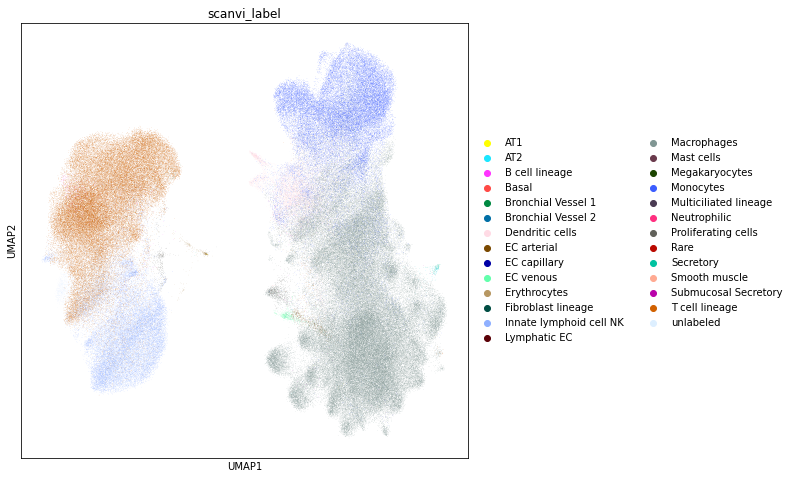

In [32]:
sc.pl.umap(subset_immune, color=["scanvi_label"])

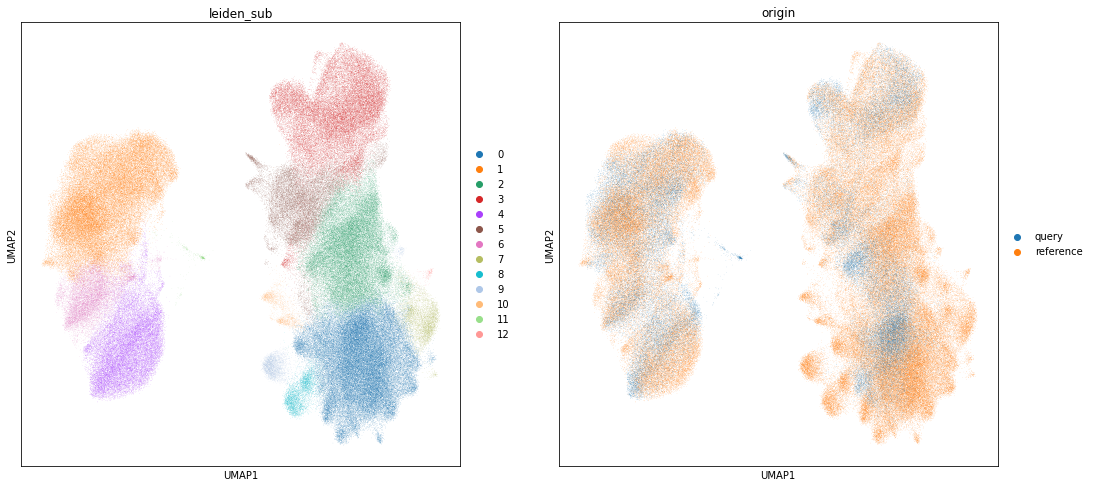

In [33]:
sc.pl.umap(subset_immune, color=["leiden_sub", "origin"])

In [98]:
subset_immune.raw.var.index = subset_immune.raw.var["gene_symbols-0"]

In [99]:
subset_immune.raw.var_names

CategoricalIndex(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR', 'CFH',
                  'FUCA2', 'GCLC', 'NFYA',
                  ...
                  'RP11-11M20.4', nan, nan, nan, nan, nan, 'LLNLR-245B6.1',
                  'CTD-2060L22.1', 'RP11-107E5.4', 'RP11-299P2.2'],
                 categories=['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1', 'A2ML1', 'A2ML1-AS1', 'A2ML1-AS2', ...], ordered=False, name='gene_symbols-0', dtype='category', length=33694)

In [97]:
subset_immune.raw.var.index

CategoricalIndex(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR', 'CFH',
                  'FUCA2', 'GCLC', 'NFYA',
                  ...
                  'RP11-11M20.4', nan, nan, nan, nan, nan, 'LLNLR-245B6.1',
                  'CTD-2060L22.1', 'RP11-107E5.4', 'RP11-299P2.2'],
                 categories=['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1', 'A2ML1', 'A2ML1-AS1', 'A2ML1-AS2', ...], ordered=False, name='gene_symbols-0', dtype='category', length=33694)

In [ ]:
sc.tl.rank_genes_groups(subset_immune, 'leiden_sub', method='t-test', key_added = "t-test", use_raw=True)
sc.pl.rank_genes_groups(subset_immune, n_genes=25, sharey=False, key = "t-test", gene_symbols = "gene_symbols-0")

In [ ]:
sc.tl.filter_rank_genes_groups(subset_immune, min_fold_change=3, key="t-test", use_raw=True)

In [ ]:
subset_immune.uns["rank_genes_groups_filtered"]

In [ ]:
# visualize results
sc.pl.rank_genes_groups(subset_immune, key='rank_genes_groups_filtered')

In [ ]:
sc.get.rank_genes_groups_df(subset_immune, key='rank_genes_groups_filtered')

In [ ]:
# visualize results using dotplot
sc.pl.rank_genes_groups_dotplot(subset_immune, n_genes=5, key='rank_genes_groups_filtered',  gene_symbols = "gene_symbols-0")

In [59]:
sc.logging.print_versions()


-----
anndata     0.7.5
scanpy      1.8.2
sinfo       0.3.1
-----
PIL                 8.1.0
anndata             0.7.5
anyio               NA
attr                20.3.0
babel               2.9.0
backcall            0.2.0
brotli              1.0.9
certifi             2020.12.05
cffi                1.14.4
chardet             4.0.0
cloudpickle         1.6.0
constants           NA
cycler              0.10.0
cython_runtime      NA
dask                2020.12.0
dateutil            2.8.1
decorator           4.4.2
future_fstrings     NA
google              NA
h5py                2.10.0
highs_wrapper       NA
idna                2.10
igraph              0.8.3
ipykernel           5.4.3
ipython_genutils    0.2.0
ipywidgets          7.6.3
jedi                0.18.0
jinja2              2.11.2
joblib              1.0.0
json5               NA
jsonschema          3.2.0
jupyter_server      1.2.1
jupyterlab_server   2.1.2
kiwisolver          1.3.1
leidenalg           0.8.3
llvmlite            0.35.0
louv